<a href="https://colab.research.google.com/github/mehmoodanas/Day-1/blob/main/Day1_Data_foundations_practical_tasks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 1 - Data foundations practical tasks
***

These tasks cover data preparation, visualization and feature engineering topics.

## Explore the datasets and answer the questions below.
#### Here are some guidlines and advices you should consider:
* you can add as many cells as is comfortable for you for each answer
* some questions require your explanation. Add a cell and choose a markdown option in the menu
* when you are making plots, please add labels to the axes

For this task you will use red wine dataset

In [81]:
import pandas as pd
import numpy as np
wine_data = pd.read_csv('winequality-red.csv', sep = ';')
wine_data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [82]:
wine_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [83]:
wine_data.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [84]:
wine_data.isnull().values.sum()

np.int64(0)

### 1. `quality` attribute in the DataFrame has a score from 0 to 10. How many observations (rows) belong to each score level?

In [85]:
wine_data.groupby('quality').size().reset_index(name='count')

,quality,count
0,3,10
1,4,53
2,5,681
3,6,638
4,7,199
5,8,18


### 2. Make a bar plot, where we can see distribution of the samples against quality attributes.

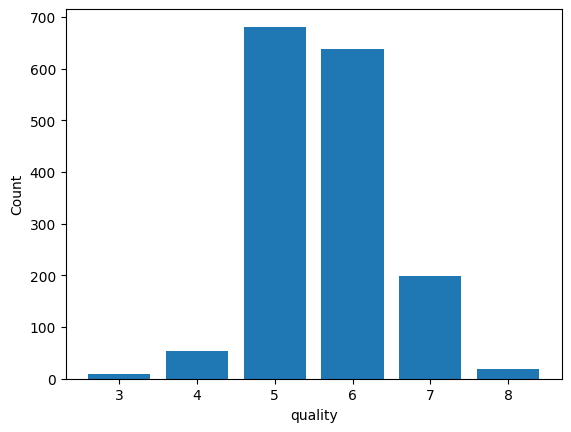

In [86]:
import matplotlib.pyplot as plt
plt.bar(wine_data['quality'].unique(), wine_data['quality'].value_counts())
plt.xlabel("quality")
plt.ylabel("Count")
plt.show()

### 3. What is the average value of each feature (column) in each `quality` score level?

In [87]:
df_mean = wine_data.groupby('quality').mean().round(2)
df_mean

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
quality,,,,,,,,,,,
3,8.36,0.88,0.17,2.64,0.12,11.00,24.90,1.0,3.40,0.57,9.96
4,7.78,0.69,0.17,2.69,0.09,12.26,36.25,1.0,3.38,0.60,10.27
5,8.17,0.58,0.24,2.53,0.09,16.98,56.51,1.0,3.30,0.62,9.90
6,8.35,0.50,0.27,2.48,0.08,15.71,40.87,1.0,3.32,0.68,10.63
7,8.87,0.40,0.38,2.72,0.08,14.05,35.02,1.0,3.29,0.74,11.47
8,8.57,0.42,0.39,2.58,0.07,13.28,33.44,1.0,3.27,0.77,12.09


### 4. What is the median value of each feature (column) in each `quality` score level?

In [88]:
df_median = wine_data.groupby('quality').median().round(2)
df_median

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
quality,,,,,,,,,,,
3,7.50,0.84,0.04,2.1,0.09,6.0,15.0,1.00,3.39,0.55,9.93
4,7.50,0.67,0.09,2.1,0.08,11.0,26.0,1.00,3.37,0.56,10.00
5,7.80,0.58,0.23,2.2,0.08,15.0,47.0,1.00,3.30,0.58,9.70
6,7.90,0.49,0.26,2.2,0.08,14.0,35.0,1.00,3.32,0.64,10.50
7,8.80,0.37,0.40,2.3,0.07,11.0,27.0,1.00,3.28,0.74,11.50
8,8.25,0.37,0.42,2.1,0.07,7.5,21.5,0.99,3.23,0.74,12.15


### 5. We can notice that for some features raw values differ significantly. Scale the data (except quality column) using Min-Max Scaling manually (create formula yourself). Then use built-in Min-Max Scaling function to validate results (display the resulting data frames separately).
#### Hint: you can use `pd.DataFrame(<your data>)` to display the result of the built-in function in a nicer way.

In [89]:
data_dim = wine_data.drop(columns='quality')
data_dim
data_manual = (data_dim - data_dim.min()) / (data_dim.max() - data_dim.min())
data_manual

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846
1,0.283186,0.520548,0.00,0.116438,0.143573,0.338028,0.215548,0.494126,0.362205,0.209581,0.215385
2,0.283186,0.438356,0.04,0.095890,0.133556,0.197183,0.169611,0.508811,0.409449,0.191617,0.215385
3,0.584071,0.109589,0.56,0.068493,0.105175,0.225352,0.190813,0.582232,0.330709,0.149701,0.215385
4,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846
...,...,...,...,...,...,...,...,...,...,...,...
1594,0.141593,0.328767,0.08,0.075342,0.130217,0.436620,0.134276,0.354626,0.559055,0.149701,0.323077
1595,0.115044,0.294521,0.10,0.089041,0.083472,0.535211,0.159011,0.370778,0.614173,0.257485,0.430769
1596,0.150442,0.267123,0.13,0.095890,0.106845,0.394366,0.120141,0.416300,0.535433,0.251497,0.400000
1597,0.115044,0.359589,0.12,0.075342,0.105175,0.436620,0.134276,0.396476,0.653543,0.227545,0.276923


In [90]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

data_scaled = scaler.fit_transform(data_dim)
pd.DataFrame(data_scaled, columns=data_dim.columns)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846
1,0.283186,0.520548,0.00,0.116438,0.143573,0.338028,0.215548,0.494126,0.362205,0.209581,0.215385
2,0.283186,0.438356,0.04,0.095890,0.133556,0.197183,0.169611,0.508811,0.409449,0.191617,0.215385
3,0.584071,0.109589,0.56,0.068493,0.105175,0.225352,0.190813,0.582232,0.330709,0.149701,0.215385
4,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846
...,...,...,...,...,...,...,...,...,...,...,...
1594,0.141593,0.328767,0.08,0.075342,0.130217,0.436620,0.134276,0.354626,0.559055,0.149701,0.323077
1595,0.115044,0.294521,0.10,0.089041,0.083472,0.535211,0.159011,0.370778,0.614173,0.257485,0.430769
1596,0.150442,0.267123,0.13,0.095890,0.106845,0.394366,0.120141,0.416300,0.535433,0.251497,0.400000
1597,0.115044,0.359589,0.12,0.075342,0.105175,0.436620,0.134276,0.396476,0.653543,0.227545,0.276923


### 6. Create correlation matrix between all variables.

In [91]:
corr = wine_data.corr().round(2)
corr

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.00,-0.26,0.67,0.11,0.09,-0.15,-0.11,0.67,-0.68,0.18,-0.06,0.12
volatile acidity,-0.26,1.00,-0.55,0.00,0.06,-0.01,0.08,0.02,0.23,-0.26,-0.20,-0.39
citric acid,0.67,-0.55,1.00,0.14,0.20,-0.06,0.04,0.36,-0.54,0.31,0.11,0.23
residual sugar,0.11,0.00,0.14,1.00,0.06,0.19,0.20,0.36,-0.09,0.01,0.04,0.01
chlorides,0.09,0.06,0.20,0.06,1.00,0.01,0.05,0.20,-0.27,0.37,-0.22,-0.13
free sulfur dioxide,-0.15,-0.01,-0.06,0.19,0.01,1.00,0.67,-0.02,0.07,0.05,-0.07,-0.05
total sulfur dioxide,-0.11,0.08,0.04,0.20,0.05,0.67,1.00,0.07,-0.07,0.04,-0.21,-0.19
density,0.67,0.02,0.36,0.36,0.20,-0.02,0.07,1.00,-0.34,0.15,-0.50,-0.17
pH,-0.68,0.23,-0.54,-0.09,-0.27,0.07,-0.07,-0.34,1.00,-0.20,0.21,-0.06
sulphates,0.18,-0.26,0.31,0.01,0.37,0.05,0.04,0.15,-0.20,1.00,0.09,0.25


### 7. Plot heatmap to see correlations.

In [92]:
corr = wine_data.corr()
corr


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.000000,-0.256131,0.671703,0.114777,0.093705,-0.153794,-0.113181,0.668047,-0.682978,0.183006,-0.061668,0.124052
volatile acidity,-0.256131,1.000000,-0.552496,0.001918,0.061298,-0.010504,0.076470,0.022026,0.234937,-0.260987,-0.202288,-0.390558
citric acid,0.671703,-0.552496,1.000000,0.143577,0.203823,-0.060978,0.035533,0.364947,-0.541904,0.312770,0.109903,0.226373
residual sugar,0.114777,0.001918,0.143577,1.000000,0.055610,0.187049,0.203028,0.355283,-0.085652,0.005527,0.042075,0.013732
chlorides,0.093705,0.061298,0.203823,0.055610,1.000000,0.005562,0.047400,0.200632,-0.265026,0.371260,-0.221141,-0.128907
free sulfur dioxide,-0.153794,-0.010504,-0.060978,0.187049,0.005562,1.000000,0.667666,-0.021946,0.070377,0.051658,-0.069408,-0.050656
total sulfur dioxide,-0.113181,0.076470,0.035533,0.203028,0.047400,0.667666,1.000000,0.071269,-0.066495,0.042947,-0.205654,-0.185100
density,0.668047,0.022026,0.364947,0.355283,0.200632,-0.021946,0.071269,1.000000,-0.341699,0.148506,-0.496180,-0.174919
pH,-0.682978,0.234937,-0.541904,-0.085652,-0.265026,0.070377,-0.066495,-0.341699,1.000000,-0.196648,0.205633,-0.057731
sulphates,0.183006,-0.260987,0.312770,0.005527,0.371260,0.051658,0.042947,0.148506,-0.196648,1.000000,0.093595,0.251397


<Axes: >

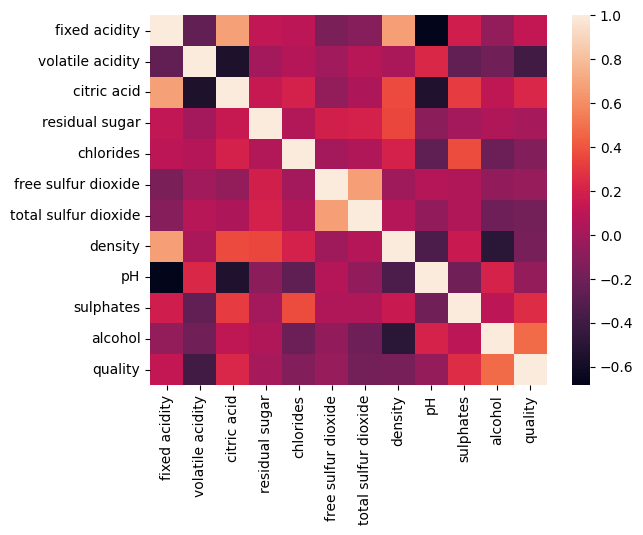

In [93]:
import seaborn as sns
sns.heatmap(corr)

### 8. Identify potential outliers in `alcohol` using the IQR rule. Flag values below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR`.

In [94]:
q1 = wine_data['alcohol'].quantile(0.25)
q3 = wine_data['alcohol'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

salary_outliers = wine_data.loc[
    (wine_data['alcohol'] < lower_fence) | (wine_data['alcohol'] > upper_fence)
].sort_values('alcohol')

print(f"Lower fence: {lower_fence:,.2f}")
print(f"Upper fence: {upper_fence:,.2f}")
salary_outliers

Lower fence: 7.10
Upper fence: 13.50


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1475,5.3,0.47,0.11,2.2,0.048,16.0,89.0,0.99182,3.54,0.88,13.566667,7
1114,5.0,0.40,0.50,4.3,0.046,29.0,80.0,0.99020,3.49,0.66,13.600000,6
1228,5.1,0.42,0.00,1.8,0.044,18.0,88.0,0.99157,3.68,0.73,13.600000,7
1132,7.4,0.36,0.34,1.8,0.075,18.0,38.0,0.99330,3.38,0.88,13.600000,7
1477,5.3,0.47,0.11,2.2,0.048,16.0,89.0,0.99182,3.54,0.88,13.600000,7
588,5.0,0.42,0.24,2.0,0.060,19.0,50.0,0.99170,3.72,0.74,14.000000,8
142,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.000000,6
144,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.000000,6
1270,5.0,0.38,0.01,1.6,0.048,26.0,60.0,0.99084,3.70,0.75,14.000000,6
821,4.9,0.42,0.00,2.1,0.048,16.0,42.0,0.99154,3.71,0.74,14.000000,7


### 9. Plot boxplots for all columns (except quality), use figure size 15x6. You can use both original and scaled data for this task. Try to interpret the data for one feature of your choice and write your observations.

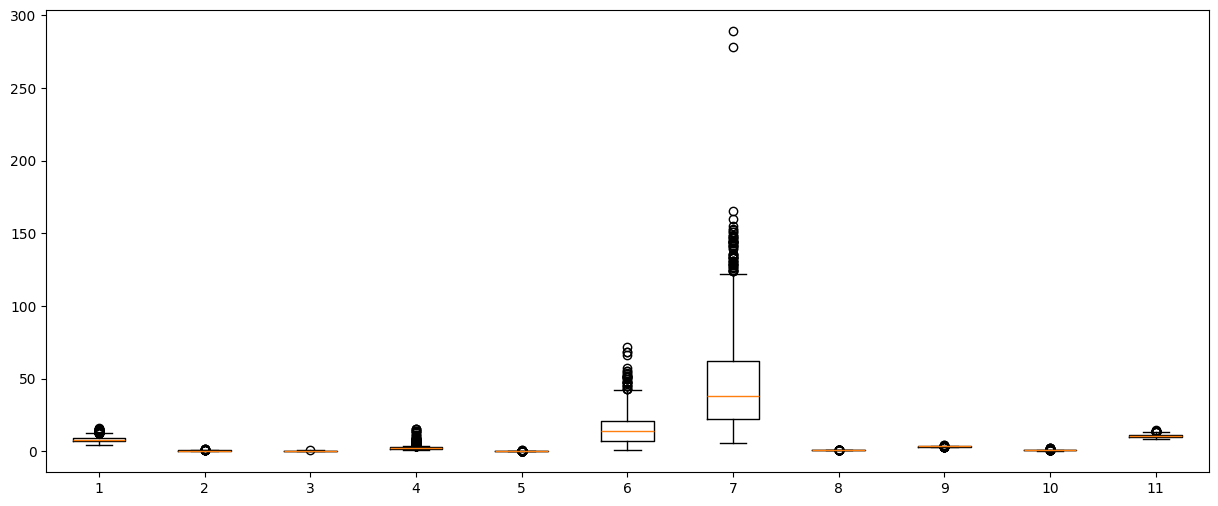

In [95]:
plt.figure(figsize=(15, 6))
plt.boxplot(wine_data.drop(columns='quality'))
plt.show()


### 10. Plot boxplot of Ph for each quality type.

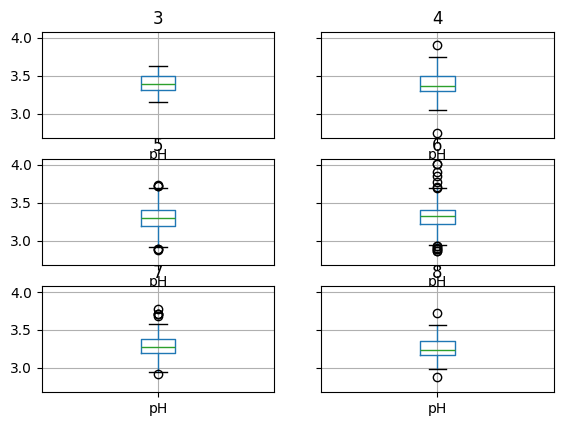

In [96]:

boxplot = wine_data.groupby('quality').boxplot(column='pH')
plt.show()


<Axes: xlabel='quality', ylabel='pH'>

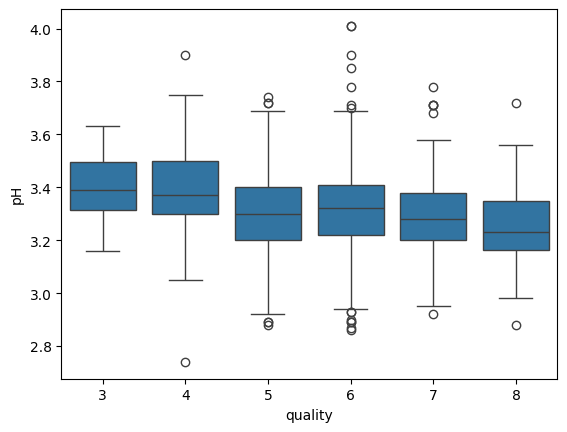

In [97]:
sns.boxplot(x='quality', y='pH', data=wine_data)

### 11. Plot a scatter plot of `quality` against the feature with the strongest correlation to it. Does alcohol content appear associated with wine quality?

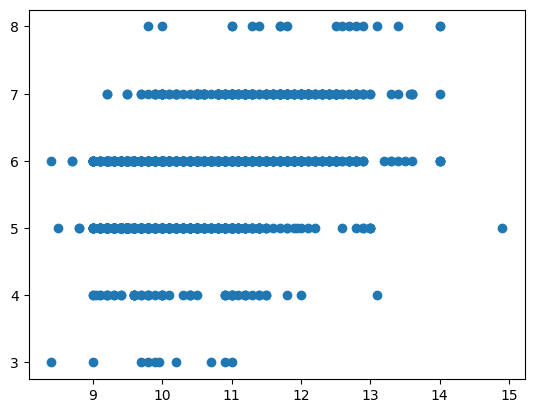

In [98]:
corr['quality'].sort_values(ascending=False)
plt.scatter(wine_data['alcohol'], wine_data['quality'])
plt.show()

In [99]:
print('Yes, alcohol has the strongest correlation with quality (0.48). Higher-quality wines tend to have higher alcohol but there is a lot of overlap.')

Yes, alcohol has the strongest correlation with quality (0.48). Higher-quality wines tend to have higher alcohol but there is a lot of overlap.


### 12. Plot scatter plot for any two columns and color it by `quality` number. Add color legend and write your observations.

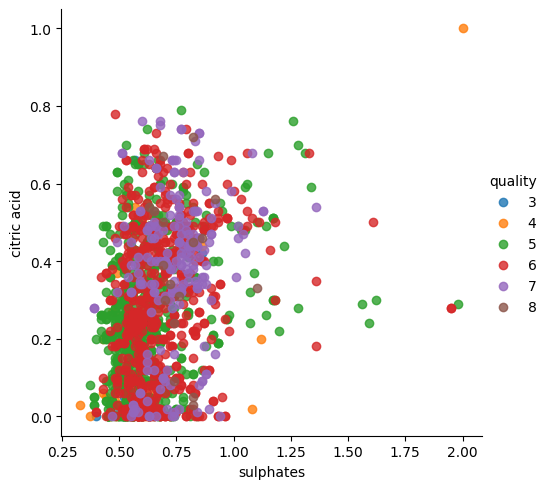

In [100]:
import seaborn as sns
sns.lmplot(x='sulphates', y='citric acid', data=wine_data, hue='quality', fit_reg=False)

In [101]:
print('Quality 7 (purple) points sit mostly at higher citric acid (about 0.3 to 0.6) and sulphates around 0.6 to 0.9. Quality 5 (green) and 6 (red) points are spread out and many are at low citric acid near 0. The colors overlap a lot so sulphates and citric acid alone can’t separate the quality levels. There are a few outliers with very high sulphates (above 1.5) such as the quality 4 point at about 2.0.')

Quality 7 (purple) points sit mostly at higher citric acid (about 0.3 to 0.6) and sulphates around 0.6 to 0.9. Quality 5 (green) and 6 (red) points are spread out and many are at low citric acid near 0. The colors overlap a lot so sulphates and citric acid alone can’t separate the quality levels. There are a few outliers with very high sulphates (above 1.5) such as the quality 4 point at about 2.0.


### 13. Create X, y for independent variables (all except `quality`) and target variable `quality`, perform k-fold k=3 split on them and calculate and print out the length of training set and testing set for each fold

In [102]:
from sklearn.model_selection import KFold

X = wine_data.drop(columns='quality')
y = wine_data['quality']

k = 3
kf = KFold(n_splits=k, shuffle=True, random_state=42)

In [103]:
fold = 1
for train_index, test_index in kf.split(X):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    print(f"Fold {fold}:")
    print("Training set length:", len(X_train))
    print("Testing set length:", len(X_test))
    print()
    fold += 1

Fold 1:
Training set length: 1066
Testing set length: 533

Fold 2:
Training set length: 1066
Testing set length: 533

Fold 3:
Training set length: 1066
Testing set length: 533



### 14. Create two new features:
- Sulfur dioxide ratio (`free sulfur dioxide` / `total sulfur dioxide`)
- Total acidity (`fixed acidity` + `volatile acidity` + `citric acid`)

In [104]:
wine_data['sulfur dioxide ratio'] = wine_data['free sulfur dioxide'] / wine_data['total sulfur dioxide']
wine_data['total acidity'] = wine_data['fixed acidity'] + wine_data['volatile acidity'] + wine_data['citric acid']
wine_data[['sulfur dioxide ratio', 'total acidity']].head().round(2)

,sulfur dioxide ratio,total acidity
0,0.32,8.10
1,0.37,8.68
2,0.28,8.60
3,0.28,12.04
4,0.32,8.10


### 15. Create a sample dataset with dates for a whole week. Extract day of the week with `dayofweek` function (0=Monday, 6=Sunday). Additionally flag weekends by creating another new `is_weekend` feature.

In [105]:
date_data = {'date': ['2023-11-06', '2023-11-07', '2023-11-08', '2023-11-09', '2023-11-10', '2023-11-11', '2023-11-12']}
df = pd.DataFrame(date_data)

df['date'] = pd.to_datetime(df['date'])

df['day_of_week'] = df['date'].dt.dayofweek
df['is_weekend'] = df['day_of_week'].apply(lambda x: 1 if x >= 5 else 0)

df

,date,day_of_week,is_weekend
0,2023-11-06,0,0
1,2023-11-07,1,0
2,2023-11-08,2,0
3,2023-11-09,3,0
4,2023-11-10,4,0
5,2023-11-11,5,1
6,2023-11-12,6,1
